In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
data_path = Path("data/raw/global_power_plant_database.csv")

if not data_path.exists():
    data_path = Path("../data/raw/global_power_plant_database.csv")

df = pd.read_csv(data_path, low_memory=False)

print("Dataset successfully loaded.")

ParserError: Error tokenizing data. C error: Expected 36 fields in line 13343, saw 37


In [ ]:
pd.DataFrame({
    "Empty cells": df.isna().sum(),
    "NO-ESTIMATION": (df == "NO-ESTIMATION").sum(),
    "Valid values": ((df != "NO-ESTIMATION") & df.notna()).sum()
})

,Empty cells,NO-ESTIMATION,Valid values
country,0,0,34936
country_long,0,0,34936
name,0,0,34936
gppd_idnr,0,0,34936
capacity_mw,0,0,34936
latitude,0,0,34936
longitude,0,0,34936
primary_fuel,0,0,34936
other_fuel1,32992,0,1944
other_fuel2,34660,0,276


In [ ]:
for year in range(2013, 2018):
    generation = f"generation_gwh_{year}"
    estimated = f"estimated_generation_gwh_{year}"
    note = f"estimated_generation_note_{year}"

    condition = (
        df[generation].isna() &
        df[estimated].isna() &
        (df[note] == "NO-ESTIMATION")
    )

    print(year, condition.sum())

2013 14932
2014 14195
2015 13158
2016 12306
2017 1539


In [ ]:
years = range(2013, 2019)

generation_cols = [f"generation_gwh_{y}" for y in years]
estimated_cols = [f"estimated_generation_gwh_{y}" for y in range(2013, 2018)]

all_generation_cols = generation_cols + estimated_cols

# True if at least one generation value exists
has_generation_data = df[all_generation_cols].notna().any(axis=1)

print("Power plants with generation data:", has_generation_data.sum())
print("Power plants without generation data:", (~has_generation_data).sum())

Power plants with generation data: 33443
Power plants without generation data: 1493


In [ ]:
no_generation_data =df[~has_generation_data]
no_generation_data

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017
6,AFG,Afghanistan,Northwest Kabul Power Plant Afghanistan,GEODB0040540,42.000,34.5638,69.1134,Gas,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION
16,ALB,Albania,Vlora,WRI1002176,98.000,40.4874,19.4340,Other,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION
90,ATA,Antarctica,McMurdo Station Generator,WRI1023843,6.600,-77.8470,166.6605,Oil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION
91,ATA,Antarctica,Ross Island,WRI1022458,1.000,-77.8428,166.7271,Wind,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION
509,AUS,Australia,Inkerman Sugar Mill,AUS0000145,10.500,-19.6422,147.4016,Biomass,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34615,URY,Uruguay,ZENDALEATHER,URY0000837,3.720,-34.8467,-56.2347,Gas,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION
34761,VNM,Vietnam,Gia Lai sugar-cane,WRI1030753,12.000,13.4257,108.4200,Biomass,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION
34794,VNM,Vietnam,Lap Vo Rice Husk Power Plant,WRI1030735,10.000,10.3492,105.5700,Biomass,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION
34911,ESH,Western Sahara,Dakhla IC Power Plant Western Sahara,GEODB0042583,23.400,23.6816,-15.9594,Oil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION


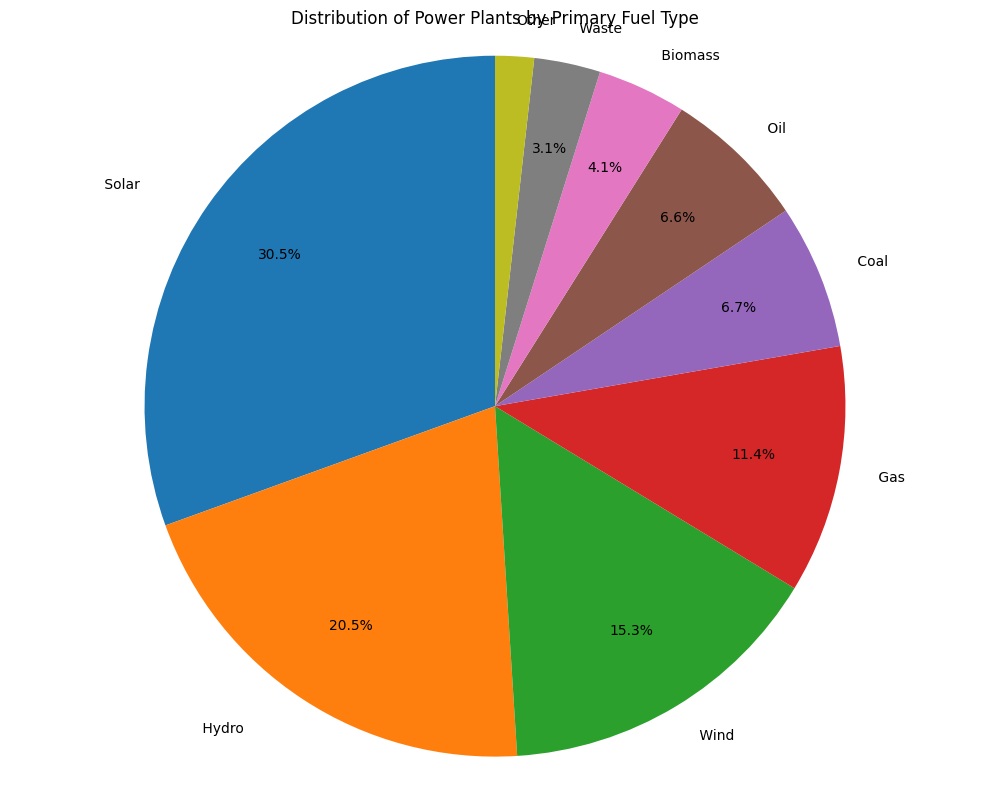

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your dataset
df = pd.read_csv("../data/processed/global_power_plant_database.csv")

# Remove any whitespace from column names
df.columns = df.columns.str.strip()

# Count power plants by primary fuel
fuel_counts = df["primary_fuel"].value_counts()

# Group fuel types representing less than 3% into "Other"
threshold = 0.03 * fuel_counts.sum()

major_fuels = fuel_counts[fuel_counts >= threshold]
minor_fuels = fuel_counts[fuel_counts < threshold]

fuel_counts_grouped = pd.concat([
    major_fuels,
    pd.Series({"Other": minor_fuels.sum()})
])

plt.figure(figsize=(10, 8))

plt.pie(
    fuel_counts_grouped,
    labels=fuel_counts_grouped.index,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
    startangle=90,
    pctdistance=0.75,
    labeldistance=1.1
)

plt.title("Distribution of Power Plants by Primary Fuel Type")
plt.axis("equal")
plt.tight_layout()
plt.show()